# 05 · Error analysis
Project doc (Phase 7): analyse *mixed sentiment, negation, ambiguous language, multiple topics per review and
context-dependent expressions*. We tag every test review with these properties and compare error rates.

Change `PRED_FILE` to analyse a BERT run instead of the baseline.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, OUT = ROOT / "data" / "processed", ROOT / "outputs"
LABELS = ["negative", "neutral", "positive"]
PRED_FILE = OUT / "predictions_baseline_text_plus_rating.csv"      # e.g. OUT / "predictions_bert_<tag>.csv"
pd.set_option("display.max_colwidth", 260)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

d = pd.read_csv(PRED_FILE)
d["error"] = d.true != d.pred
print(f"{PRED_FILE.name}: {len(d):,} test reviews, accuracy {100 * (1 - d.error.mean()):.2f}%, {d.error.sum()} errors")

predictions_baseline_text_plus_rating.csv: 4,923 test reviews, accuracy 94.27%, 282 errors


## 1. Where do the errors go?

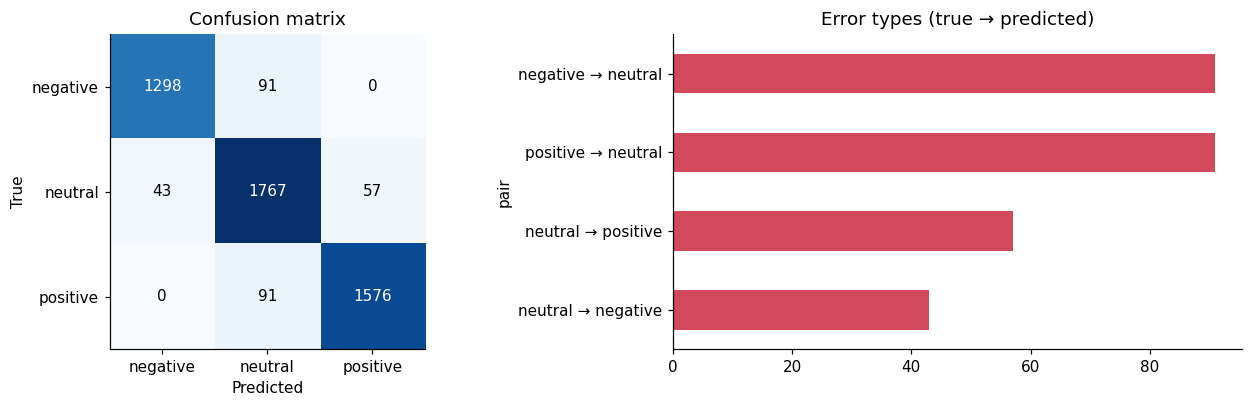

In [2]:
cm = pd.crosstab(d.true.map(dict(enumerate(LABELS))), d.pred.map(dict(enumerate(LABELS)))).reindex(index=LABELS, columns=LABELS, fill_value=0)
err_pairs = (d[d.error].assign(pair=lambda x: x.true.map(dict(enumerate(LABELS))) + " → " + x.pred.map(dict(enumerate(LABELS))))
             .pair.value_counts())
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].imshow(cm.values, cmap="Blues"); ax[0].set_xticks(range(3), LABELS); ax[0].set_yticks(range(3), LABELS)
ax[0].set(xlabel="Predicted", ylabel="True", title="Confusion matrix")
for i in range(3):
    for j in range(3): ax[0].text(j, i, cm.values[i, j], ha="center", va="center", color="white" if cm.values[i, j] > cm.values.max() / 2 else "black")
err_pairs.sort_values().plot.barh(ax=ax[1], color="#D1495B"); ax[1].set_title("Error types (true → predicted)")
plt.tight_layout(); plt.show()

## 2. Tag the reviews
Simple, transparent, rule-based tags (extend the word lists for real data):
* **contrast marker** – "but / however / although…" (possible mixed sentiment)
* **negation** – "not / never / n't / without…" (flips polarity)
* **ambiguous rating band** – rating 2.4–3.6, where Neutral overlaps both neighbours
* **rating–label disagreement** – high rating but non-positive label (or low rating, non-negative)
* **suspected label error** – flagged by the cleanlab audit in notebook 03

In [3]:
CONTRAST = r"\b(?:but|however|on the other hand|that said|although|though|even so|yet)\b"
NEGATION = r"\b(?:not|never|no|nothing|hardly|barely|without)\b|n't\b"
t = d.review_text.str.lower()
d["contrast marker"] = t.str.contains(CONTRAST)
d["negation"] = t.str.contains(NEGATION)
d["ambiguous rating band (2.4–3.6)"] = d.rating_score.between(2.4, 3.6)
d["rating–label disagreement"] = ((d.rating_score >= 3.6) & (d.true != 2)) | ((d.rating_score <= 2.4) & (d.true != 0))
d["long review (>200 chars)"] = d.review_text.str.len() > 200
issues = OUT / "label_issues.csv"
if issues.exists():
    d["suspected label error (03)"] = d.review_id.isin(pd.read_csv(issues).review_id)

tags = [c for c in d.columns if c not in ("review_id", "review_text", "rating_score", "true", "pred", "error") and not c.startswith("p_")]
tab = pd.DataFrame([{"tag": c, "reviews": int(d[c].sum()), "error rate %": round(100 * d.loc[d[c], "error"].mean(), 1),
                     "share of all errors %": round(100 * d.loc[d[c], "error"].sum() / max(d.error.sum(), 1), 1)}
                    for c in tags if d[c].sum()]).sort_values("share of all errors %", ascending=False)
base = 100 * d.error.mean()
tab

,tag,reviews,error rate %,share of all errors %
5,suspected label error (03),231,100.0,81.9
2,ambiguous rating band (2.4–3.6),2459,7.6,66.3
1,negation,2759,6.5,63.1
0,contrast marker,1703,5.6,34.0
3,rating–label disagreement,91,98.9,31.9
4,long review (>200 chars),1360,4.6,22.3


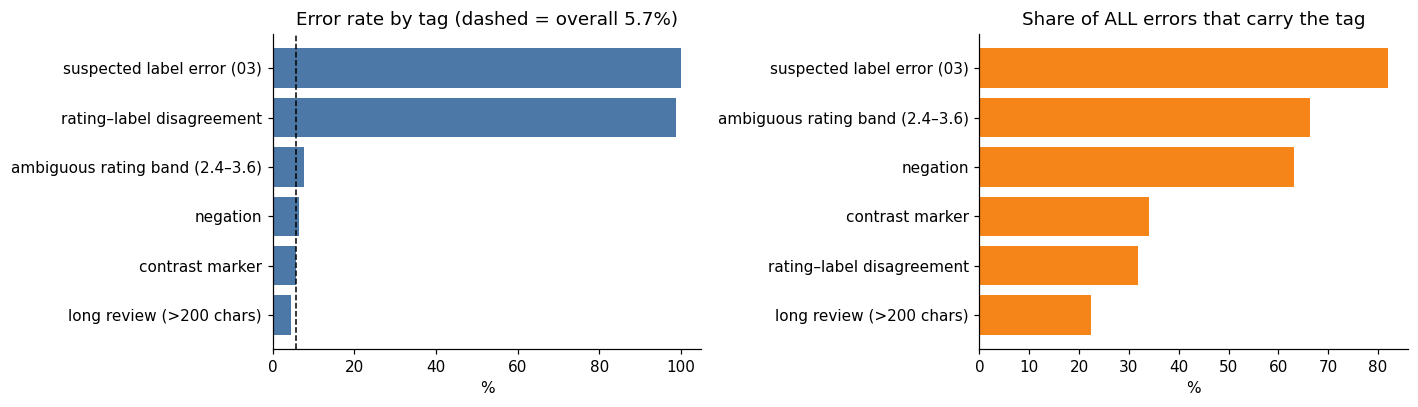

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
tt = tab.sort_values("error rate %")
ax[0].barh(tt.tag, tt["error rate %"], color="#4C78A8"); ax[0].axvline(base, color="k", ls="--", lw=1)
ax[0].set(title=f"Error rate by tag (dashed = overall {base:.1f}%)", xlabel="%")
tt = tab.sort_values("share of all errors %")
ax[1].barh(tt.tag, tt["share of all errors %"], color="#F58518"); ax[1].set(title="Share of ALL errors that carry the tag", xlabel="%")
plt.tight_layout(); plt.show()

## 3. Read the errors
Tag statistics point to *where* to look; reading examples shows *why*.

In [5]:
def show(mask, n=6, title=""):
    print(f"── {title} ({int(mask.sum())} reviews) ──")
    s = d[mask].sample(min(n, int(mask.sum())), random_state=1)
    s = s.assign(true=s.true.map(dict(enumerate(LABELS))), pred=s.pred.map(dict(enumerate(LABELS))))
    return s[["review_text", "rating_score", "true", "pred"]]

show(d.error & d.get("suspected label error (03)", False), title="Errors the audit flags as probable LABEL mistakes")

── Errors the audit flags as probable LABEL mistakes (231 reviews) ──


,review_text,rating_score,true,pred
1778,"This hotel was a fine, if unremarkable, choice for our time in Southampton. That said, overall the carpet was adequately maintained, about what we expected. Plus, the fitness facilities was basic but functional for what we paid.",2.6,negative,neutral
3219,"Nothing about our visit to Edinburgh stood out much either way. That said, overall the bathroom area was adequately maintained, about what we expected. On the other hand, the fitness facilities was basic but functional, nothing more and nothing less.",2.9,positive,neutral
3491,"We were disappointed that the location was disappointingly out of the way. On top of that, the rate we paid left a lot to be desired; we found better options nearby for less. Not sure we'd come back.",2.2,neutral,negative
4813,"The breakfast was acceptable for what we paid. On top of that, overall our arrival experience was fine, about what we expected. Also, the pricing was in line with similar hotels, nothing more and nothing less.",2.8,negative,neutral
3810,"The dining options was acceptable, nothing more and nothing less. On top of that, we were disappointed that the pricing was hard to justify. Meanwhile, getting around from the hotel was acceptable for what we paid.",2.4,negative,neutral
1982,"The location was ideally situated, and public transport links were right outside. Plus, honestly, the carpet was sparkling clean.",4.3,neutral,positive


In [6]:
show(d.error & ~d.get("suspected label error (03)", pd.Series(False, index=d.index)), title="Remaining errors (not flagged as label noise)")

── Remaining errors (not flagged as label noise) (51 reviews) ──


,review_text,rating_score,true,pred
2137,"Overall getting checked in was acceptable, about what we expected. Meanwhile, the spa left a lot to be desired; it needed a serious refurbishment.",2.3,neutral,negative
431,"I'd describe the service team as reasonably polite — service was there when needed. In addition, the room service was decent, nothing more and nothing less.",3.5,positive,neutral
4539,"We had a wonderful time during our stay in Glasgow. Also, the lounge was adequate, nothing more and nothing less. On the other hand, the cost of the stay was about what we expected for what we paid.",3.6,positive,neutral
2206,"Our suite was passably clean for what we paid. Meanwhile, our arrival experience was chaotic, which really affected our stay.",2.4,negative,neutral
3243,"Our time in Aberdeen got off to a rocky start here. In addition, the front desk team was fairly professional, nothing more and nothing less.",2.3,negative,neutral
4030,"I'd describe the dining options as fine — there wasn't much variety but it was edible. Plus, honestly, the neighborhood was perfectly placed for exploring.",3.7,positive,neutral


In [7]:
show(d.error & d["negation"], title="Errors on reviews containing negation")

── Errors on reviews containing negation (178 reviews) ──


,review_text,rating_score,true,pred
4146,"Nothing about our visit to Glasgow stood out much either way. On top of that, the overall décor was clean enough, nothing more and nothing less. I'd describe getting checked in as unremarkable — nothing out of the ordinary happened.",3.3,negative,neutral
3175,"Our stay in Southampton was fairly ordinary. On the other hand, i'd describe our arrival experience as acceptable — nothing out of the ordinary happened.",3.0,negative,neutral
595,"The pool was adequate, nothing more and nothing less. On the other hand, overall the overall décor was adequately maintained, about what we expected.",3.4,positive,neutral
1968,I'd describe the check-in process as acceptable — nothing out of the ordinary happened. Not sure we'd come back.,2.3,negative,neutral
1490,"Our stay in London was fairly ordinary. In addition, getting checked in was acceptable, nothing more and nothing less. That said, i'd describe the fitness facilities as nothing special — we only used it briefly but it seemed fine.",2.5,positive,neutral
3481,"This hotel was a fine, if unremarkable, choice for our time in Glasgow. The neighborhood was reasonably central for what we paid. Plus, the pricing was reasonable enough, nothing more and nothing less.",2.6,positive,neutral


## 4. What to do about it
| Finding | Action |
|---|---|
| Most errors are neutral ↔ positive/negative confusions | Neutral is the hardest class; consider collapsing to a 5-point score or reviewing the neutral guideline |
| A large share of errors is flagged label noise | Re-label a sample; train on cleaned labels (notebook 03/04); report raw + cleaned accuracy |
| Negation / contrast errors | Compare against BERT (04): contextual models handle these better than bag-of-words |
| Rating–label disagreements | Decide whether the label should follow the text or the rating and document it |